In [1]:
import numpy as np
import scipy

import cupy as cp
import cupyx.scipy

import astropy.units as u
from astropy.io import fits
from matplotlib.patches import Rectangle, Circle
from pathlib import Path
from IPython.display import clear_output, display, HTML
display(HTML("<style>.container { width:90% !important; }</style>")) # just making the notebook cells wider
from datetime import datetime
today = int(datetime.today().strftime('%Y%m%d'))

from importlib import reload
import time


import ray
if not ray.is_initialized():
    ray.init(log_to_driver=False)
    

import logging, sys
poppy_log = logging.getLogger('poppy')
poppy_log.setLevel('DEBUG')
logging.basicConfig(stream=sys.stdout, level=logging.INFO)

poppy_log.disabled = True

import warnings
warnings.filterwarnings("ignore")

import cgi_phasec_poppy
    
from math_module import xp, ensure_np_array
import iefc_2dm 
import utils
from imshows import *

data_dir = iefc_2dm.iefc_data_dir
response_dir = data_dir/'response-data'

dm1_flat = fits.getdata('spc_wide_band4_flattened_dm1.fits')
dm2_flat = fits.getdata('spc_wide_band4_flattened_dm2.fits')


2024-03-26 08:46:47,541	INFO worker.py:1636 -- Started a local Ray instance.


INFO:numexpr.utils:Note: NumExpr detected 64 cores but "NUMEXPR_MAX_THREADS" not set, so enforcing safe limit of 8.
INFO:numexpr.utils:NumExpr defaulting to 8 threads.


In [2]:
reload(cgi_phasec_poppy.source_flux)
wavelength_c = 825e-9*u.m

nwaves = 3
bandwidth = 3.6/100
minwave = wavelength_c * (1 - bandwidth/2)
maxwave = wavelength_c * (1 + bandwidth/2)
wavelengths = np.linspace( minwave, maxwave, nwaves )


In [3]:
reload(cgi_phasec_poppy.cgi)
reload(cgi_phasec_poppy.parallelized_cgi)

rayCGI = ray.remote(cgi_phasec_poppy.cgi.CGI) # make a ray actor class from the original CGI class  

kwargs = {
    'cgi_mode':'spc-wide',
    'npsf':150,
    'use_pupil_defocus':True,
    'use_opds':True,
    'polaxis':0,
}

actors = []
for i in range(nwaves):
    actors.append(rayCGI.options(num_cpus=2, num_gpus=1/8).remote(**kwargs))
    actors[i].setattr.remote('wavelength', wavelengths[i])

In [13]:
mode.Imax_ref

array(0.01882027)

Computing each monochromatic image.
Computing each monochromatic image.


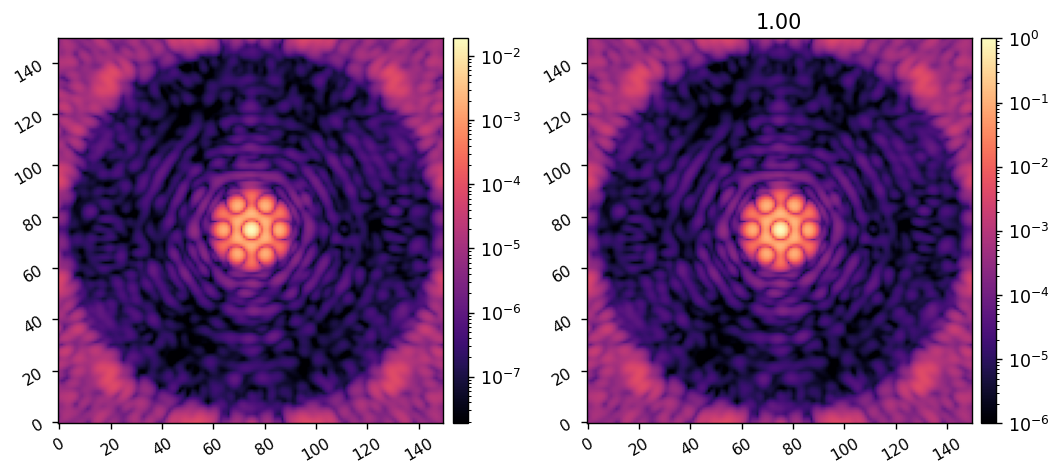

Computing each monochromatic image.


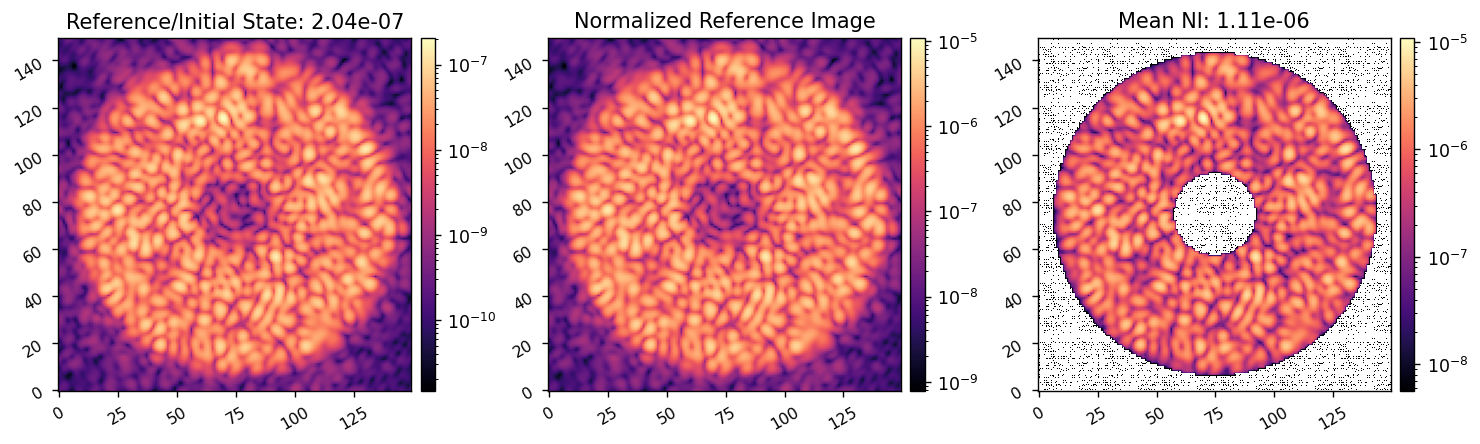

In [4]:
reload(cgi_phasec_poppy.parallelized_cgi)
mode = cgi_phasec_poppy.parallelized_cgi.ParallelizedCGI(actors=actors, 
                                                         dm1_ref=2*dm1_flat, 
                                                        #  dm2_ref=dm2_flat, 
                                                         )
mode.set_actor_attr('use_fpm',False)
raw_im = mode.snap(quiet=False)

mode.Imax_ref = xp.max(raw_im.max())
ref_unocc_im = mode.snap(quiet=False)
imshow2(raw_im, ref_unocc_im, '', f'{xp.max(ref_unocc_im):.2f}', 
        lognorm=True, vmin1=mode.Imax_ref*1e-6, vmin2=1e-6)

mode.set_actor_attr('use_fpm',True)
ref_im = mode.snap(quiet=False)

control_mask = utils.create_annular_focal_plane_mask(mode, inner_radius=5.4, outer_radius=20.6, edge=None)
mean_ni = xp.mean(ref_im[control_mask])
imshow3(ref_im*mode.Imax_ref, ref_im, ref_im*control_mask, 
        f'Reference/Initial State: {xp.max(ref_im*mode.Imax_ref):.2e}', 
        'Normalized Reference Image',
        f'Mean NI: {mean_ni:.2e}',
        lognorm=True,)

# Create calibration and probe modes

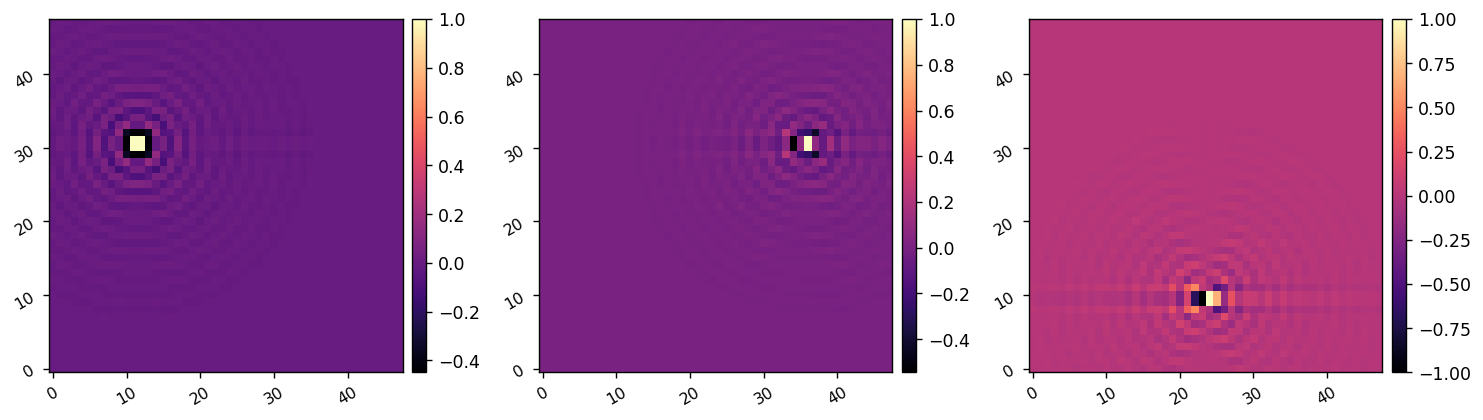

(4096, 4608)


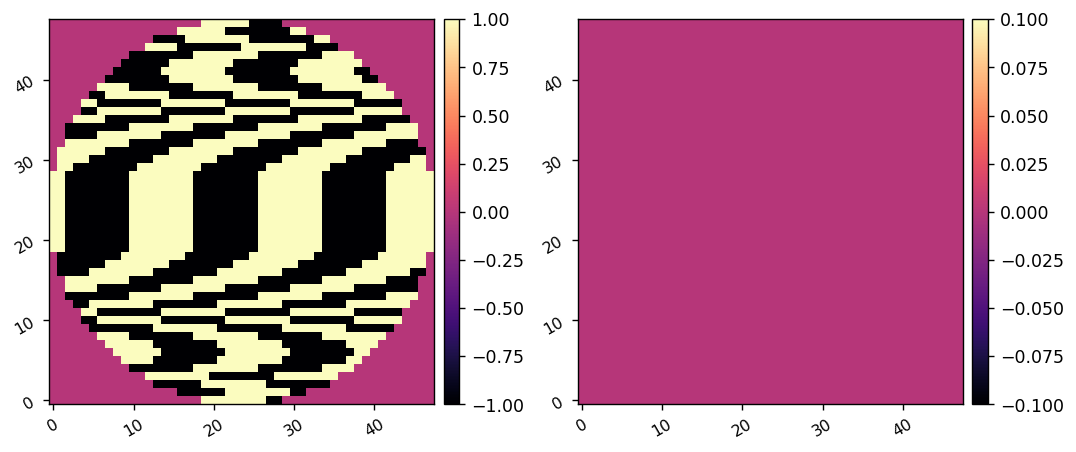

In [5]:
probe_modes = utils.create_fourier_probes(mode, control_mask, fourier_sampling=0.2,
                                          shift=[(-12,7), (12,7),(0,-14), (0,0)], nprobes=3,
                                           use_weighting=True)
imshow3(probe_modes[0], probe_modes[1], probe_modes[2])

calib_modes = utils.create_hadamard_modes(mode.dm_mask, ndms=2)
Nmodes = calib_modes.shape[0]
print(calib_modes.shape)
i = 8
imshow2(calib_modes[i,:mode.Nact**2].reshape(mode.Nact,mode.Nact), calib_modes[i+mode.Nacts,mode.Nact**2:].reshape(mode.Nact,mode.Nact))



Calibrating iEFC...
	Calibrated mode 1/2 in 11.702s
	Calibrated mode 2/2 in 23.387s

Calibration complete.


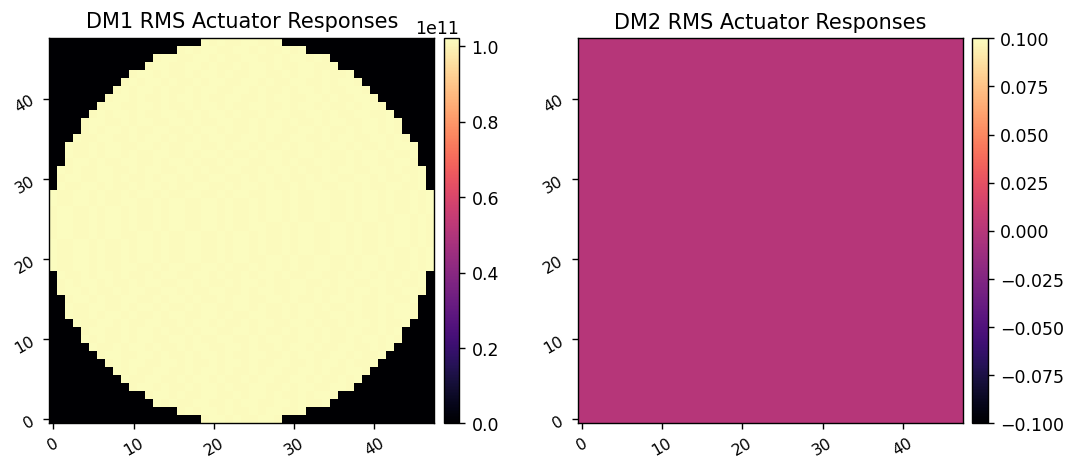

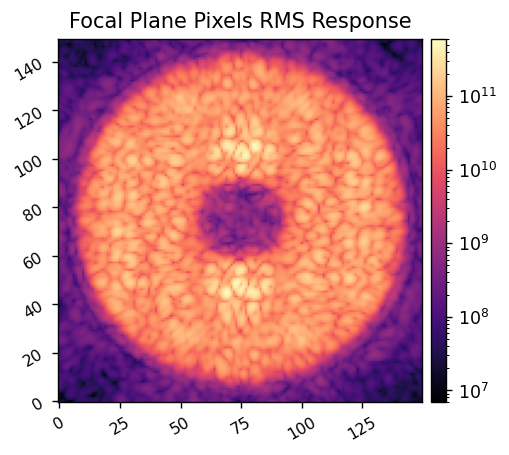

Saved data to:  /npool/nvme/kianmilani/roman-cgi-iefc-data/response-data/test_response_matrix_20240325.fits


In [6]:
reload(iefc_2dm)

probe_amp = 20e-9
calib_amp = 5e-9

response_matrix, response_cube, calib_amps = iefc_2dm.calibrate(mode, 
                                                                control_mask,
                                                                probe_amp, probe_modes, 
                                                                calib_amp, calib_modes[191:193], 
                                                                return_all=True, 
            #                                                     plot_responses=False,
                                                                )

utils.save_fits(response_dir/f'test_response_matrix_{today}.fits', response_matrix)
# utils.save_fits(response_dir/f'test_response_cube_{today}.fits', response_cube)


In [6]:
date = 20230912
date = 20230913
date = 20230918
date = 20230920
# date = 20230921
date = 20240213
date = 20240325
response_matrix = xp.array(fits.getdata(response_dir/f'spc_wide_band4b_had_modes_response_matrix_{date}.fits'))
# response_cube = xp.array(fits.getdata(data_dir/response_dir/f'spc_wide_825_poke_modes_response_cube_{date}.fits'))

9045054986191.5


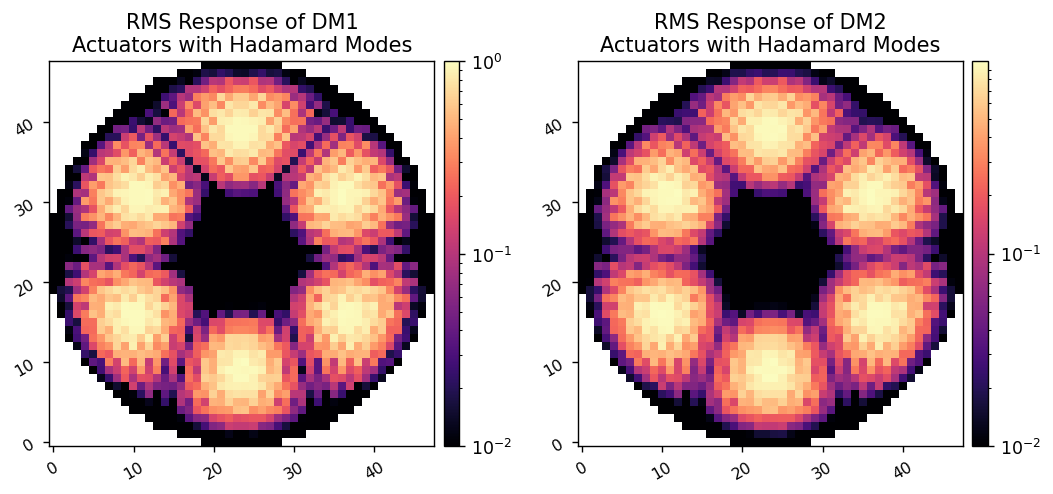

In [7]:
dm_response = xp.sqrt(xp.mean(response_matrix.dot(xp.array(calib_modes))**2, axis=0))
dm1_response = dm_response[:mode.Nact**2].reshape(mode.Nact, mode.Nact)/dm_response.max()
dm2_response = dm_response[mode.Nact**2:].reshape(mode.Nact, mode.Nact)/dm_response.max()

print(dm_response.max())
imshow2(dm1_response, dm2_response, 
        'RMS Response of DM1\nActuators with Hadamard Modes', 'RMS Response of DM2\nActuators with Hadamard Modes',
        lognorm=True, vmin1=0.01, vmin2=0.01,
        )


# Run IEFC

In [13]:
mode.reset_dms()
images = xp.array([ref_im])
dm1_commands = xp.array([mode.get_dm1()])
dm2_commands = xp.array([mode.get_dm2()])
regs = xp.array([])


In [ ]:
dm1_commands = xp.array(fits.getdata(response_dir/f'spc_wfov_band4b_15_dm1_commands_{today}.fits'))
dm2_commands = xp.array(fits.getdata(response_dir/f'spc_wfov_band4b_15_dm2_commands_{today}.fits'))
images = xp.array(fits.getdata(response_dir/f'spc_wfov_band4b_15_images_{today}.fits'))
regs = fits.getdata(response_dir/f'spc_wfov_band4b_15_regs_{today}.fits')

mode.set_dm1(ensure_np_array(dm1_commands[-1]))
mode.set_dm2(ensure_np_array(dm2_commands[-1]))

Running iEFC...
	Closed-loop iteration 25 / 27
False
False


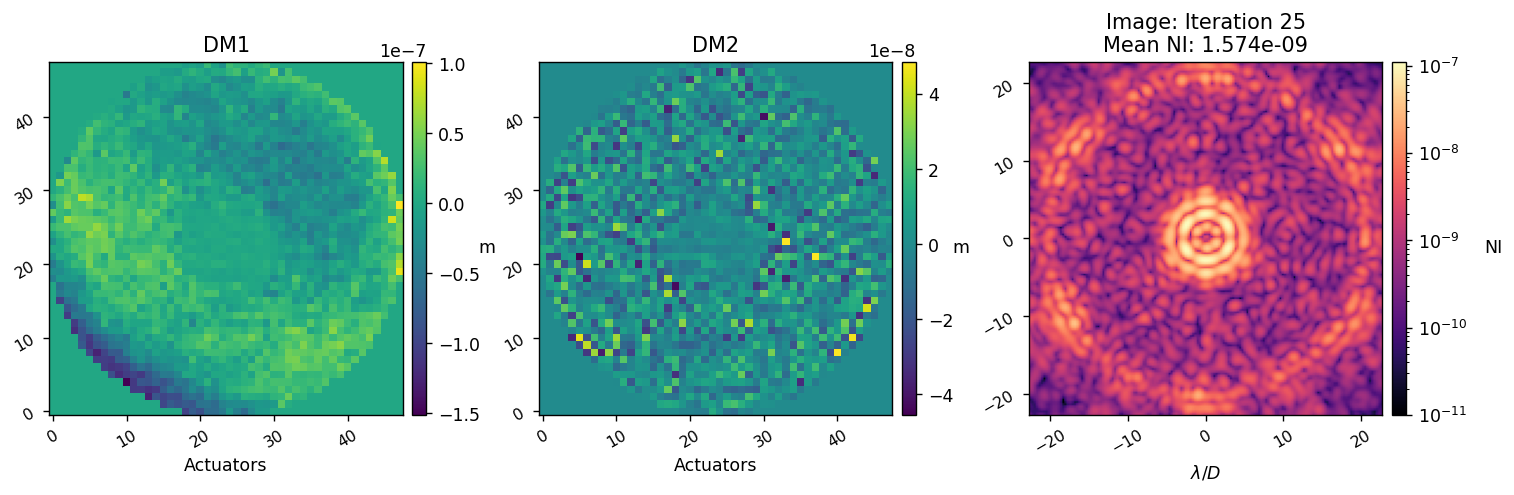

	Closed-loop iteration 26 / 27
False
False


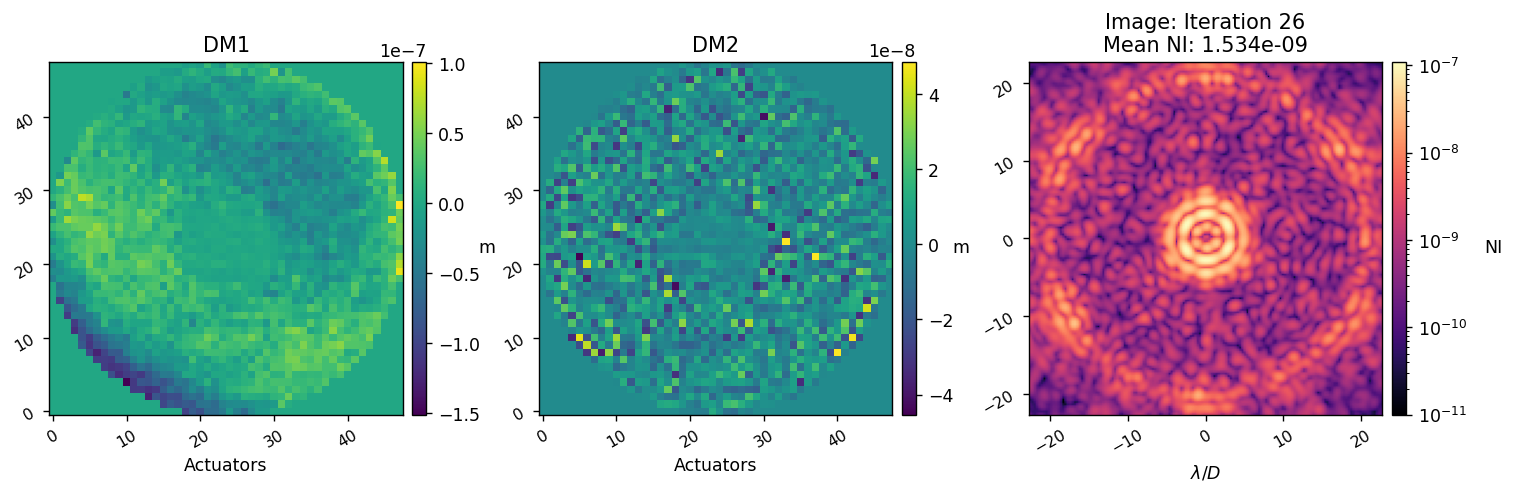

	Closed-loop iteration 27 / 27
False
False


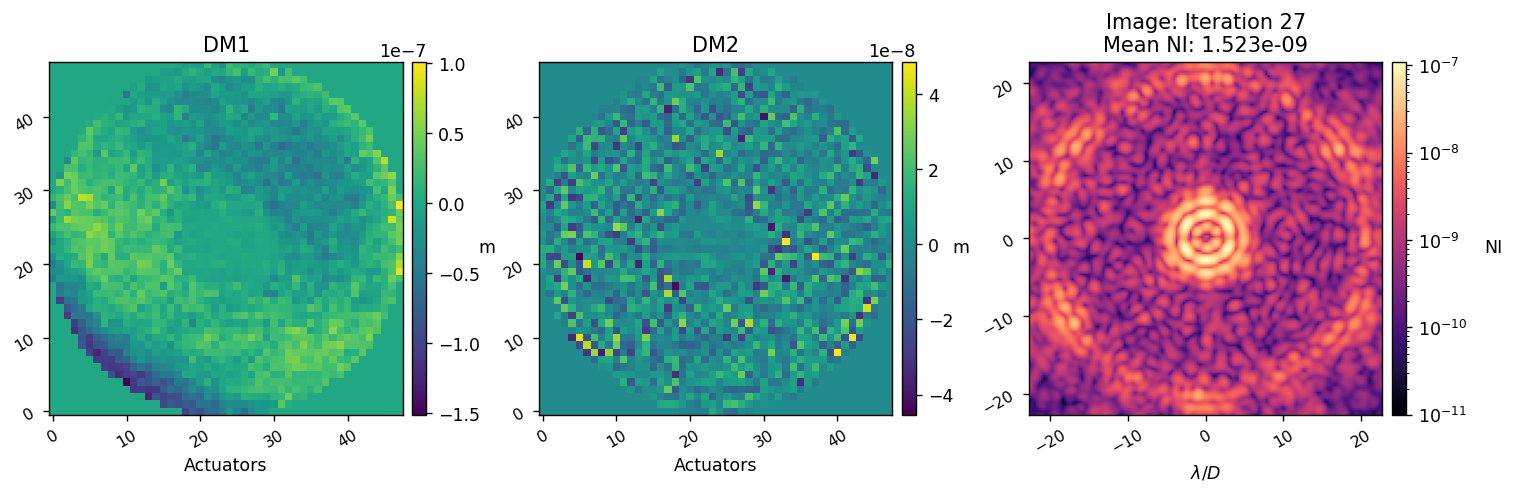

Closed loop for given control matrix completed in 22.955s.


In [23]:
reload(iefc_2dm)
reload(utils)

reg_fun = utils.beta_reg
reg_conds = -2
reg_conds = -2.5
# reg_conds = -3.5
# reg_conds = -4
# reg_conds = -4.5
# reg_conds = -5
# reg_conds = -6

probe_amp = 2.5e-9/2

images, dm1_commands, dm2_commands, regs = iefc_2dm.run(mode, 
                                                        response_matrix,
                                                        reg_fun, reg_conds, 
                                                        probe_modes, 
                                                        probe_amp, 
                                                        calib_modes,
                                                        control_mask, 
                                                        num_iterations=3, 
                                                        loop_gain=0.5, 
                                                        leakage=0,
                                                        plot_all=True,
                                                        plot_radial_contrast=False,
                                                        old_images=images,
                                                        old_dm1_commands=dm1_commands,
                                                        old_dm2_commands=dm2_commands,
                                                        old_regs=regs,
                                                        )

In [19]:
utils.save_fits(response_dir/f'spc_wfov_band4b_15_dm1_commands_{today}.fits', dm1_commands)
utils.save_fits(response_dir/f'spc_wfov_band4b_15_dm2_commands_{today}.fits', dm2_commands)
utils.save_fits(response_dir/f'spc_wfov_band4b_15_images_{today}.fits', images)
utils.save_fits(response_dir/f'spc_wfov_band4b_15_regs_{today}.fits', regs)

Saved data to:  /npool/nvme/kianmilani/roman-cgi-iefc-data/response-data/spc_wfov_band4b_15_dm1_commands_20240326.fits
Saved data to:  /npool/nvme/kianmilani/roman-cgi-iefc-data/response-data/spc_wfov_band4b_15_dm2_commands_20240326.fits
Saved data to:  /npool/nvme/kianmilani/roman-cgi-iefc-data/response-data/spc_wfov_band4b_15_images_20240326.fits
Saved data to:  /npool/nvme/kianmilani/roman-cgi-iefc-data/response-data/spc_wfov_band4b_15_regs_20240326.fits
